# ThreatGraph AI - Detector de Componentes de Arquitetura

**Equipe**
Joalisson Borges, Luis Gustavo Santini, Marina Souza Lucas, Diego Santos.

Este notebook Colab treina um detector YOLO supervisionado para identificar componentes em diagramas de arquitetura usados pelo MVP do ThreatGraph AI.

Fonte do dataset planejada para este projeto:

- Bucket no Hugging Face: `hf://buckets/lgsantini1/stride-architecture-components-v1-bucket`
- Página pública: https://huggingface.co/buckets/lgsantini1/stride-architecture-components-v1-bucket
- Formato: YOLO com `train/`, `val/`, `test/` e `data.yaml`
- Classes: 32 rótulos de arquitetura em nuvem e limites de confiança

Artefatos finais exportados por este notebook:

- `best.pt` para `models/best.pt`
- `model_metadata.json` para `models/model_metadata.json`
- `detected_components_sample.json` para testes de integração ou demonstrações do backend


## Observações de Runtime

Use um runtime com GPU no Colab:

`Runtime > Change runtime type > T4 GPU` ou superior.

O bucket tem vários GB, então a primeira sincronização pode demorar. Este notebook usa o Google Drive como cache persistente do dataset:

- Primeira execução: sincroniza o bucket do Hugging Face em `/content/drive/MyDrive/datasets/...`
- A cada novo runtime do Colab: copia o dataset em cache do Drive para `/content/...`
- O treinamento usa `/content/...` porque o armazenamento local do runtime é mais rápido do que ler milhares de imagens diretamente do Drive

Se o bucket se tornar privado, defina `HF_TOKEN` no ambiente ou faça login com `hf auth login` antes da sincronização.


In [1]:
%pip install -q -U "huggingface_hub[hf_xet]" ultralytics PyYAML pandas matplotlib Pillow==11.0.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.0/41.0 kB 3.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 8.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.4/4.4 MB 120.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 82.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 120.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 137.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 721.1/721.1 kB 57.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 3.0.4 which is incompatible.
cudf-cu12 26.2.1 requires pandas<2.4.0,>=2.0, but you have pandas 3.0.4 which is incompatible.
da

In [2]:
from __future__ import annotations

import json
import os
import random
import shutil
import subprocess
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display
from PIL import Image
from ultralytics import YOLO

SEED = 42
random.seed(SEED)

BUCKET_URI = "hf://buckets/lgsantini1/stride-architecture-components-v1-bucket"

# Estratégia de cache persistente para o Google Colab:
# - DRIVE_DATASET_DIR mantém o dataset entre runtimes.
# - LOCAL_DATASET_DIR é usado no treinamento porque /content é mais rápido que o Drive.
USE_GOOGLE_DRIVE_CACHE = True
COPY_DATASET_TO_LOCAL_RUNTIME = True
FORCE_RESYNC_DATASET = False
FORCE_LOCAL_DATASET_COPY = False

DRIVE_MOUNT_POINT = Path("/content/drive")
DRIVE_DATASET_DIR = DRIVE_MOUNT_POINT / "MyDrive" / "datasets" / "stride-architecture-components-v1"
LOCAL_DATASET_DIR = Path("/content/stride-architecture-components-v1")

DATASET_DIR = LOCAL_DATASET_DIR
EXPORT_DIR = Path("/content/threatgraph-export")
RUNS_DIR = Path("/content/runs/threatgraph")

BASE_MODEL = "yolov8n.pt"
RUN_NAME = "stride_architecture_components_yolov8n"
IMG_SIZE = 960
EPOCHS = 60
BATCH = 8
PATIENCE = 12

print(f"Bucket source: {BUCKET_URI}")
print(f"Drive dataset cache: {DRIVE_DATASET_DIR}")
print(f"Local training dataset: {LOCAL_DATASET_DIR}")
print(f"Export target: {EXPORT_DIR}")


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Bucket source: hf://buckets/lgsantini1/stride-architecture-components-v1-bucket
Drive dataset cache: /content/drive/MyDrive/datasets/stride-architecture-components-v1
Local training dataset: /content/stride-architecture-components-v1
Export target: /content/threatgraph-export


## Opcional: Autenticar no Hugging Face

A página atual do bucket parece pública. Mantenha esta célula para cenários de bucket privado ou limite de requisições.

No Colab, você pode definir `HF_TOKEN` nos secrets ou colar o token quando solicitado por `hf auth login`.


In [3]:
hf_token = os.environ.get("HF_TOKEN")
if hf_token:
    subprocess.run(["hf", "auth", "login", "--token", hf_token], check=False)
else:
    print("HF_TOKEN not set. Continuing as anonymous user.")


HF_TOKEN not set. Continuing as anonymous user.


## Preparar Dataset

Este notebook mantém o dataset persistente no Google Drive e depois o copia para o runtime do Colab antes do treinamento.

Por que usar essa configuração:

- `/content` é temporário e é apagado quando o runtime é reiniciado.
- O Google Drive persiste entre sessões do Colab.
- Treinar diretamente a partir do Drive pode ser mais lento para YOLO porque datasets normalmente contêm muitos arquivos pequenos de imagem e label.
- O fluxo recomendado é: bucket Hugging Face -> cache no Google Drive -> cópia local em `/content` -> treinamento YOLO.

Para forçar uma nova sincronização do bucket, defina `FORCE_RESYNC_DATASET = True`.

Para forçar uma nova cópia do Drive para `/content`, defina `FORCE_LOCAL_DATASET_COPY = True`.


In [4]:
from pathlib import Path
import shutil
import subprocess
import time


LOCAL_COPY_MARKER = ".local_copy_complete"


def dataset_is_available(dataset_dir: Path) -> bool:
    return (dataset_dir / "data.yaml").exists()


def local_dataset_copy_is_complete(local_dir: Path) -> bool:
    return dataset_is_available(local_dir) and (local_dir / LOCAL_COPY_MARKER).exists()


def format_bytes(num_bytes: int) -> str:
    units = ["B", "KB", "MB", "GB", "TB"]
    value = float(num_bytes)

    for unit in units:
        if value < 1024:
            return f"{value:.2f} {unit}"
        value /= 1024

    return f"{value:.2f} PB"


def show_local_dataset_status(label: str, dataset_dir: Path) -> None:
    """
    Mostra status apenas do dataset local.
    Evitamos usar isso no Google Drive porque du/find no Drive pode ser muito lento.
    """
    print(f"\n[{label}] {dataset_dir}", flush=True)

    if not dataset_dir.exists():
        print("Pasta ainda não existe.", flush=True)
        return

    try:
        subprocess.run(["du", "-sh", str(dataset_dir)], check=False)
        subprocess.run(
            f"find '{dataset_dir}' -type f | wc -l",
            shell=True,
            check=False,
        )
    except Exception as error:
        print(f"Could not inspect dataset status: {error}", flush=True)


def mount_google_drive(mount_point: Path = DRIVE_MOUNT_POINT) -> None:
    """Mount Google Drive in Colab only when the Drive cache is enabled."""
    try:
        from google.colab import drive
    except ImportError as error:
        raise RuntimeError(
            "USE_GOOGLE_DRIVE_CACHE=True requires Google Colab. "
            "If you are running locally, set USE_GOOGLE_DRIVE_CACHE=False."
        ) from error

    if (mount_point / "MyDrive").exists():
        print(f"Google Drive already mounted at {mount_point}.", flush=True)
        return

    print(f"Mounting Google Drive at {mount_point}...", flush=True)
    drive.mount(str(mount_point))


def sync_bucket(bucket_uri: str, dataset_dir: Path, force: bool = False) -> None:
    dataset_dir.parent.mkdir(parents=True, exist_ok=True)

    if dataset_is_available(dataset_dir) and not force:
        print(f"Dataset already found at {dataset_dir}. Skipping bucket sync.", flush=True)
        return

    if force and dataset_dir.exists():
        print(f"FORCE_RESYNC_DATASET=True. Removing existing dataset at {dataset_dir}.", flush=True)
        shutil.rmtree(dataset_dir)

    print(f"Syncing {bucket_uri} -> {dataset_dir}", flush=True)

    try:
        subprocess.run(
            ["hf", "buckets", "sync", bucket_uri, str(dataset_dir)],
            check=True,
        )
    except Exception as cli_error:
        print(f"CLI sync failed: {cli_error}", flush=True)
        print("Trying Python sync_bucket fallback...", flush=True)
        from huggingface_hub import sync_bucket as hf_sync_bucket

        hf_sync_bucket(bucket_uri, str(dataset_dir))

    if not dataset_is_available(dataset_dir):
        raise FileNotFoundError(
            f"Bucket sync finished, but data.yaml was not found at {dataset_dir}"
        )


def copy_file_with_progress(
    source_file: Path,
    target_file: Path,
    chunk_size: int = 8 * 1024 * 1024,
) -> int:
    """
    Copia um arquivo em chunks.
    Retorna a quantidade de bytes copiados.
    """
    target_file.parent.mkdir(parents=True, exist_ok=True)

    source_size = source_file.stat().st_size

    if target_file.exists() and target_file.stat().st_size == source_size:
        return 0

    temp_file = target_file.with_name(target_file.name + ".tmp_copy")

    if temp_file.exists():
        temp_file.unlink()

    copied = 0
    last_print = time.time()

    with source_file.open("rb") as src, temp_file.open("wb") as dst:
        while True:
            chunk = src.read(chunk_size)

            if not chunk:
                break

            dst.write(chunk)
            copied += len(chunk)

            now = time.time()
            if source_size >= 64 * 1024 * 1024 and now - last_print >= 3:
                percent = copied / source_size * 100 if source_size else 100
                print(
                    f"  copiando arquivo grande: {source_file.name} "
                    f"{format_bytes(copied)} / {format_bytes(source_size)} "
                    f"({percent:.1f}%)",
                    flush=True,
                )
                last_print = now

    shutil.copystat(source_file, temp_file)
    temp_file.replace(target_file)

    return copied


def copy_dataset_to_local(source_dir: Path, local_dir: Path, force: bool = False) -> None:
    if local_dataset_copy_is_complete(local_dir) and not force:
        print(f"Local dataset already copied and marked complete at {local_dir}. Skipping local copy.", flush=True)
        show_local_dataset_status("Local dataset", local_dir)
        return

    if not dataset_is_available(source_dir):
        raise FileNotFoundError(f"Missing source dataset at {source_dir}")

    if force and local_dir.exists():
        print(f"FORCE_LOCAL_DATASET_COPY=True. Removing existing local dataset at {local_dir}.", flush=True)
        shutil.rmtree(local_dir)

    local_dir.mkdir(parents=True, exist_ok=True)

    marker_path = local_dir / LOCAL_COPY_MARKER
    if marker_path.exists():
        marker_path.unlink()

    print("\nCopying dataset from persistent cache to local runtime with Python progress:", flush=True)
    print(f"{source_dir} -> {local_dir}", flush=True)
    print("This resumes partial copies and prints progress as files are copied.", flush=True)

    start_time = time.time()
    copied_files = 0
    skipped_files = 0
    copied_bytes = 0

    for source_file in source_dir.rglob("*"):
        if not source_file.is_file():
            continue

        relative_path = source_file.relative_to(source_dir)
        target_file = local_dir / relative_path

        before_size = target_file.stat().st_size if target_file.exists() else -1
        source_size = source_file.stat().st_size

        bytes_written = copy_file_with_progress(source_file, target_file)

        if bytes_written == 0 and before_size == source_size:
            skipped_files += 1
        else:
            copied_files += 1
            copied_bytes += bytes_written

        total_seen = copied_files + skipped_files

        if total_seen % 100 == 0:
            elapsed = time.time() - start_time
            speed = copied_bytes / elapsed if elapsed > 0 else 0

            print(
                f"Progress: {total_seen} files processed | "
                f"copied: {copied_files} | "
                f"skipped/resumed: {skipped_files} | "
                f"new data copied: {format_bytes(copied_bytes)} | "
                f"avg speed: {format_bytes(speed)}/s",
                flush=True,
            )

    if not dataset_is_available(local_dir):
        raise FileNotFoundError(
            f"Local copy finished, but data.yaml was not found at {local_dir}"
        )

    marker_path.write_text(
        f"Local copy completed at {time.strftime('%Y-%m-%d %H:%M:%S')}\n",
        encoding="utf-8",
    )

    elapsed = time.time() - start_time
    speed = copied_bytes / elapsed if elapsed > 0 else 0

    print("\nLocal copy completed.", flush=True)
    print(f"Files copied: {copied_files}", flush=True)
    print(f"Files skipped/resumed: {skipped_files}", flush=True)
    print(f"New data copied: {format_bytes(copied_bytes)}", flush=True)
    print(f"Elapsed: {elapsed:.1f}s", flush=True)
    print(f"Average copy speed: {format_bytes(speed)}/s", flush=True)

    show_local_dataset_status("Local dataset after copy", local_dir)


if USE_GOOGLE_DRIVE_CACHE:
    mount_google_drive(DRIVE_MOUNT_POINT)

    sync_bucket(
        BUCKET_URI,
        DRIVE_DATASET_DIR,
        force=FORCE_RESYNC_DATASET,
    )

    if COPY_DATASET_TO_LOCAL_RUNTIME:
        copy_dataset_to_local(
            DRIVE_DATASET_DIR,
            LOCAL_DATASET_DIR,
            force=FORCE_LOCAL_DATASET_COPY,
        )
        DATASET_DIR = LOCAL_DATASET_DIR
    else:
        print("COPY_DATASET_TO_LOCAL_RUNTIME=False. Training will read directly from Drive.", flush=True)
        DATASET_DIR = DRIVE_DATASET_DIR
else:
    sync_bucket(
        BUCKET_URI,
        LOCAL_DATASET_DIR,
        force=FORCE_RESYNC_DATASET,
    )
    DATASET_DIR = LOCAL_DATASET_DIR


DATA_YAML = DATASET_DIR / "data.yaml"

print("\nDataset ready.", flush=True)
print(f"Dataset ready at: {DATASET_DIR}", flush=True)
print(f"YOLO data.yaml: {DATA_YAML}", flush=True)

if DATASET_DIR == LOCAL_DATASET_DIR:
    show_local_dataset_status("Final dataset selected for training", DATASET_DIR)

Mounting Google Drive at /content/drive...
Mounted at /content/drive
Dataset already found at /content/drive/MyDrive/datasets/stride-architecture-components-v1. Skipping bucket sync.

Copying dataset from persistent cache to local runtime with Python progress:
/content/drive/MyDrive/datasets/stride-architecture-components-v1 -> /content/stride-architecture-components-v1
This resumes partial copies and prints progress as files are copied.
Progress: 100 files processed | copied: 100 | skipped/resumed: 0 | new data copied: 6.14 MB | avg speed: 527.73 KB/s
Progress: 200 files processed | copied: 200 | skipped/resumed: 0 | new data copied: 14.73 MB | avg speed: 1.20 MB/s
Progress: 300 files processed | copied: 300 | skipped/resumed: 0 | new data copied: 16.24 MB | avg speed: 936.05 KB/s
Progress: 400 files processed | copied: 400 | skipped/resumed: 0 | new data copied: 16.30 MB | avg speed: 920.18 KB/s
Progress: 500 files processed | copied: 500 | skipped/resumed: 0 | new data copied: 55.34

## Inspecionar `data.yaml`

O YOLO usa este arquivo para localizar imagens de treino/validação/teste e os nomes das classes.


In [5]:
DATA_YAML = DATASET_DIR / "data.yaml"

if not DATA_YAML.exists():
    raise FileNotFoundError(f"Missing data.yaml at {DATA_YAML}")

data_config = yaml.safe_load(DATA_YAML.read_text())
raw_names = data_config.get("names", [])

if isinstance(raw_names, dict):
    class_names = [raw_names[index] for index in sorted(raw_names)]
else:
    class_names = list(raw_names)

print(f"Dataset config: {DATA_YAML}")
print(f"Class count: {len(class_names)}")
pd.DataFrame({"id": range(len(class_names)), "class_name": class_names})


Dataset config: /content/stride-architecture-components-v1/data.yaml
Class count: 32


,id,class_name
0,0,actor_user
1,1,actor_admin
2,2,edge_ddos_protection
3,3,edge_cdn
4,4,edge_waf
5,5,edge_gateway
6,6,edge_portal
7,7,external_entry_point
8,8,integration_orchestrator
9,9,integration_messaging


## Validar Estrutura de Pastas e Labels YOLO

Esta célula verifica as pastas esperadas e valida arquivos de label com ids de classe malformados ou bounding boxes normalizadas fora do intervalo `[0, 1]`.


In [6]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}


def list_images(split: str) -> list[Path]:
    image_dir = DATASET_DIR / split / "images"
    if not image_dir.exists():
        return []
    return sorted(path for path in image_dir.rglob("*") if path.suffix.lower() in IMAGE_EXTENSIONS)


def list_labels(split: str) -> list[Path]:
    label_dir = DATASET_DIR / split / "labels"
    if not label_dir.exists():
        return []
    return sorted(label_dir.rglob("*.txt"))


def validate_label_file(path: Path, num_classes: int) -> list[str]:
    errors = []
    for line_number, line in enumerate(path.read_text().splitlines(), start=1):
        if not line.strip():
            continue
        parts = line.split()
        if len(parts) != 5:
            errors.append(f"{path}:{line_number} expected 5 columns, got {len(parts)}")
            continue
        try:
            class_id = int(float(parts[0]))
            values = [float(value) for value in parts[1:]]
        except ValueError:
            errors.append(f"{path}:{line_number} has non-numeric values")
            continue
        if class_id < 0 or class_id >= num_classes:
            errors.append(f"{path}:{line_number} invalid class id {class_id}")
        if any(value < 0 or value > 1 for value in values):
            errors.append(f"{path}:{line_number} has bbox outside normalized range")
    return errors


summary = []
all_errors = []

for split in ["train", "val", "test"]:
    images = list_images(split)
    labels = list_labels(split)
    summary.append({"split": split, "images": len(images), "labels": len(labels)})
    for label_path in labels:
        all_errors.extend(validate_label_file(label_path, len(class_names)))

summary_df = pd.DataFrame(summary)
display(summary_df)

if all_errors:
    print(f"Found {len(all_errors)} label issues. Showing first 20:")
    for error in all_errors[:20]:
        print("-", error)
    raise ValueError("Dataset validation failed.")

print("Dataset validation passed.")


,split,images,labels
0,train,1485,1490
1,val,420,420
2,test,230,230


Dataset validation passed.


## Verificação Visual

Desenhe alguns labels YOLO sobre imagens aleatórias de treino antes de gastar tempo de GPU no treinamento.


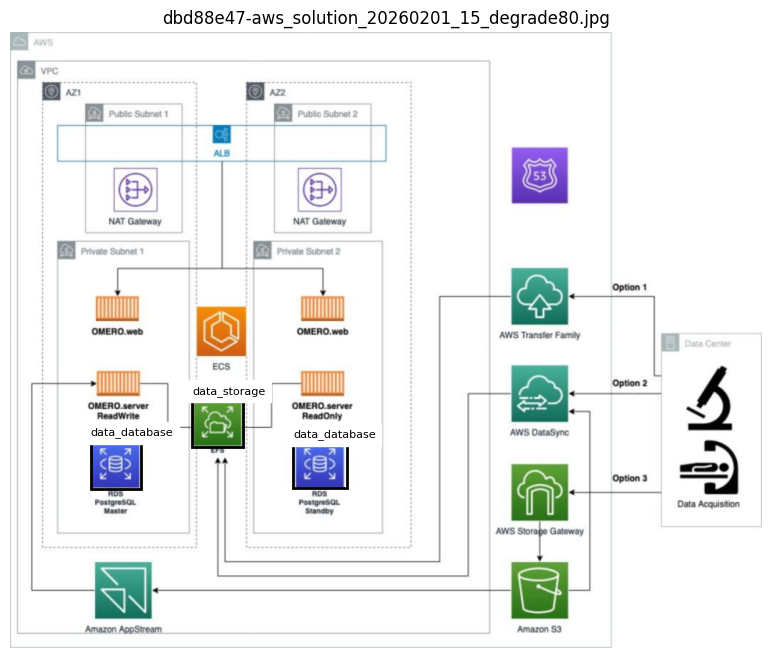

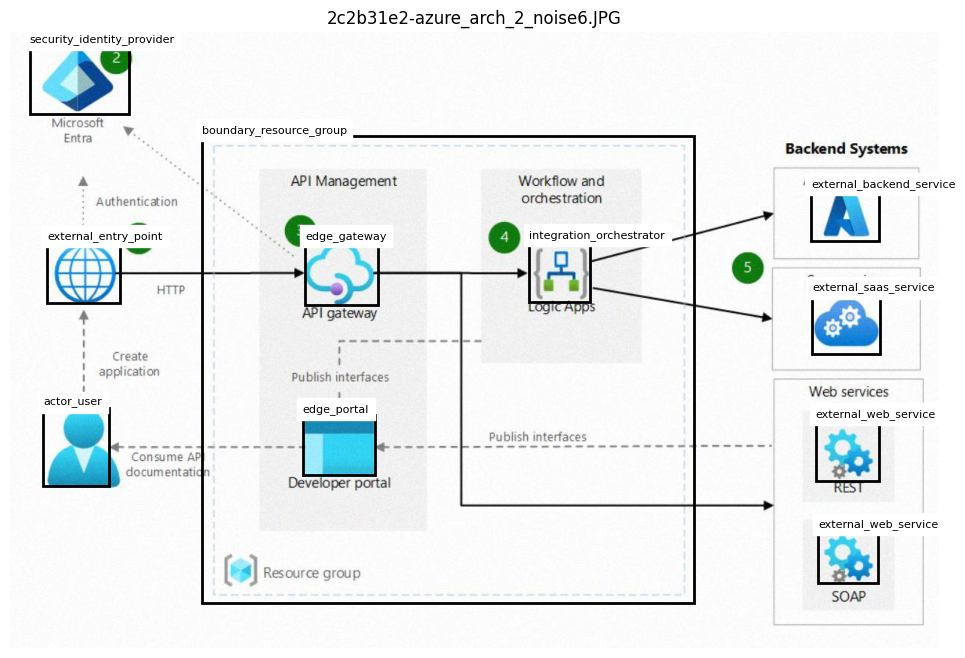

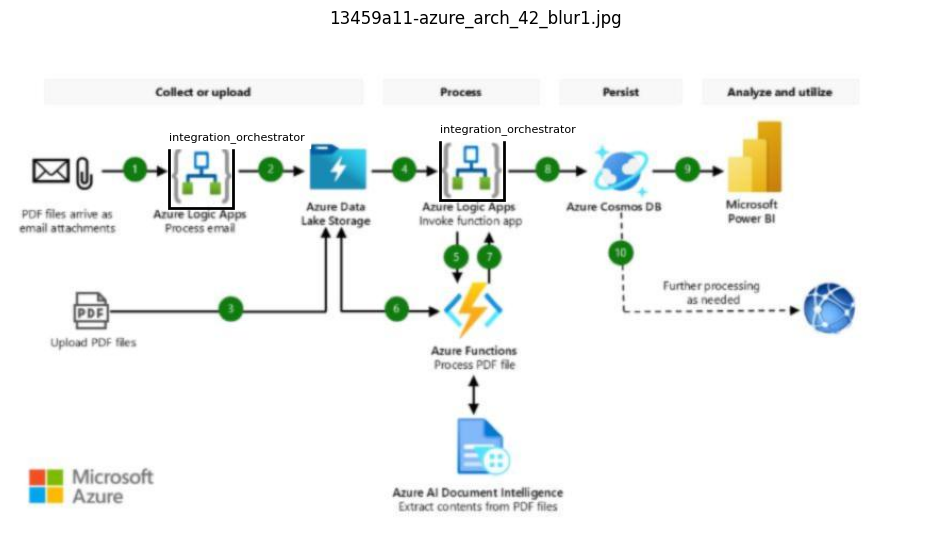

In [7]:
def label_path_for_image(image_path: Path, split: str) -> Path:
    return DATASET_DIR / split / "labels" / f"{image_path.stem}.txt"


def read_yolo_labels(label_path: Path) -> list[tuple[int, float, float, float, float]]:
    if not label_path.exists():
        return []
    labels = []
    for line in label_path.read_text().splitlines():
        if not line.strip():
            continue
        class_id, x_center, y_center, width, height = line.split()
        labels.append((int(float(class_id)), float(x_center), float(y_center), float(width), float(height)))
    return labels


def plot_labeled_image(image_path: Path, split: str) -> None:
    image = Image.open(image_path).convert("RGB")
    labels = read_yolo_labels(label_path_for_image(image_path, split))
    width, height = image.size

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)
    ax.axis("off")
    ax.set_title(image_path.name)

    for class_id, x_center, y_center, box_width, box_height in labels:
        x1 = (x_center - box_width / 2) * width
        y1 = (y_center - box_height / 2) * height
        rect_width = box_width * width
        rect_height = box_height * height
        rect = plt.Rectangle((x1, y1), rect_width, rect_height, fill=False, linewidth=2)
        ax.add_patch(rect)
        ax.text(x1, max(0, y1 - 4), class_names[class_id], fontsize=8, backgroundcolor="white")

    plt.show()


train_images = list_images("train")
for sample in random.sample(train_images, k=min(3, len(train_images))):
    plot_labeled_image(sample, "train")


,split,provider,architectures
0,test,aws,150
1,test,azure,60
2,test,unknown,20
3,train,aws,1085
4,train,azure,350
5,train,unknown,50
6,val,aws,320
7,val,azure,100


,provider,architectures
0,aws,1555
1,azure,510
2,unknown,70


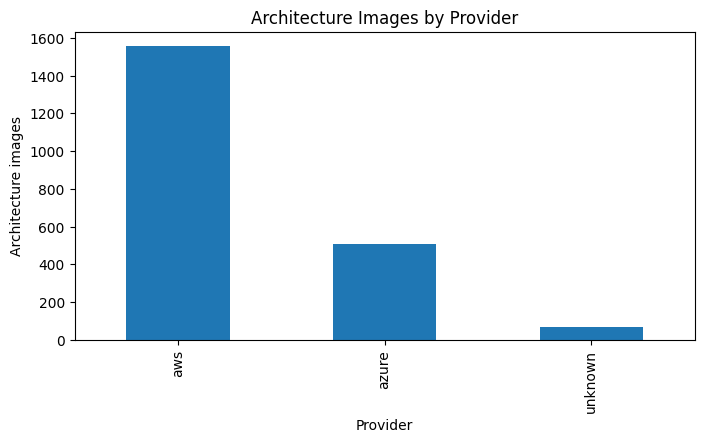

In [8]:
# Métricas do dataset por provedor: AWS vs Azure

from collections import Counter

PROVIDER_KEYWORDS = {
    "aws": ["aws", "amazon", "ec2", "s3", "lambda", "rds", "cloudfront", "eks"],
    "azure": ["azure", "aks", "blob", "appservice", "functions", "cosmos", "entra"],
}

def infer_provider_from_path(image_path: Path) -> str:
    text = str(image_path).lower()

    matches = []
    for provider, keywords in PROVIDER_KEYWORDS.items():
        if any(keyword in text for keyword in keywords):
            matches.append(provider)

    if len(matches) == 1:
        return matches[0]

    if len(matches) > 1:
        return "mixed"

    return "unknown"


provider_rows = []

for split in ["train", "val", "test"]:
    images = list_images(split)

    for image_path in images:
        provider_rows.append(
            {
                "split": split,
                "image": image_path.name,
                "provider": infer_provider_from_path(image_path),
            }
        )

provider_df = pd.DataFrame(provider_rows)

provider_summary = (
    provider_df
    .groupby(["split", "provider"])
    .size()
    .reset_index(name="architectures")
    .sort_values(["split", "provider"])
)

display(provider_summary)

overall_summary = (
    provider_df
    .groupby("provider")
    .size()
    .reset_index(name="architectures")
    .sort_values("architectures", ascending=False)
)

display(overall_summary)

overall_summary.plot(
    kind="bar",
    x="provider",
    y="architectures",
    legend=False,
    title="Architecture Images by Provider",
    figsize=(8, 4),
)

plt.xlabel("Provider")
plt.ylabel("Architecture images")
plt.show()

In [10]:
from pathlib import Path
import yaml


def list_dataset_structure(dataset_dir: Path, max_items: int = 80) -> None:
    print(f"\nDataset structure preview: {dataset_dir}")

    if not dataset_dir.exists():
        print("Dataset directory does not exist.")
        return

    dirs = sorted([p for p in dataset_dir.rglob("*") if p.is_dir()])
    for path in dirs[:max_items]:
        print(path.relative_to(dataset_dir))

    if len(dirs) > max_items:
        print(f"... showing {max_items} of {len(dirs)} directories")


def find_split_images_dir(dataset_dir: Path, split_name: str) -> str | None:
    candidates_by_split = {
        "train": [
            "train/images",
            "training/images",
        ],
        "val": [
            "val/images",
            "valid/images",
            "validation/images",
        ],
        "test": [
            "test/images",
        ],
    }

    candidates = candidates_by_split.get(split_name, [])

    for candidate in candidates:
        candidate_path = dataset_dir / candidate
        if candidate_path.exists() and candidate_path.is_dir():
            return candidate

    return None


def fix_yolo_data_yaml(data_yaml: Path) -> None:
    data_yaml = Path(data_yaml)
    dataset_dir = data_yaml.parent.resolve()

    if not data_yaml.exists():
        raise FileNotFoundError(f"data.yaml not found at {data_yaml}")

    with data_yaml.open("r", encoding="utf-8") as file:
        data = yaml.safe_load(file)

    print("\nOriginal data.yaml:")
    print(data)

    train_dir = find_split_images_dir(dataset_dir, "train")
    val_dir = find_split_images_dir(dataset_dir, "val")
    test_dir = find_split_images_dir(dataset_dir, "test")

    if train_dir is None:
        list_dataset_structure(dataset_dir)
        raise FileNotFoundError(
            f"Could not find train images directory inside {dataset_dir}. "
            "Expected something like train/images."
        )

    if val_dir is None:
        list_dataset_structure(dataset_dir)
        raise FileNotFoundError(
            f"Could not find validation images directory inside {dataset_dir}. "
            "Expected something like val/images or valid/images."
        )

    data["path"] = str(dataset_dir)
    data["train"] = train_dir
    data["val"] = val_dir

    if test_dir is not None:
        data["test"] = test_dir
    elif "test" in data:
        data.pop("test")

    with data_yaml.open("w", encoding="utf-8") as file:
        yaml.safe_dump(data, file, sort_keys=False, allow_unicode=True)

    print("\nFixed data.yaml:")
    print(data)

    print("\nResolved YOLO paths:")
    print(f"train: {dataset_dir / train_dir}")
    print(f"val:   {dataset_dir / val_dir}")

    if test_dir is not None:
        print(f"test:  {dataset_dir / test_dir}")


fix_yolo_data_yaml(DATA_YAML)


Original data.yaml:
{'path': '.', 'train': 'train/images', 'val': 'val/images', 'test': 'test/images', 'names': {0: 'actor_user', 1: 'actor_admin', 2: 'edge_ddos_protection', 3: 'edge_cdn', 4: 'edge_waf', 5: 'edge_gateway', 6: 'edge_portal', 7: 'external_entry_point', 8: 'integration_orchestrator', 9: 'integration_messaging', 10: 'compute_load_balancer', 11: 'compute_service', 12: 'compute_worker', 13: 'data_database', 14: 'data_cache', 15: 'data_storage', 16: 'security_identity_provider', 17: 'security_key_management', 18: 'obs_monitoring', 19: 'obs_audit', 20: 'external_backend_service', 21: 'external_saas_service', 22: 'external_web_service', 23: 'communication_service', 24: 'backup_service', 25: 'boundary_cloud', 26: 'boundary_region', 27: 'boundary_resource_group', 28: 'boundary_vpc_or_vnet', 29: 'boundary_subnet_public', 30: 'boundary_subnet_private', 31: 'boundary_autoscaling_group'}}

Fixed data.yaml:
{'path': '/content/stride-architecture-components-v1', 'train': 'train/image

## Treinar YOLO

Comece com `yolov8n.pt` para acelerar a iteração no hackathon. Aumente para `yolov8s.pt` ou `yolov8m.pt` se as métricas ficarem fracas e houver tempo de GPU disponível.


In [11]:
model = YOLO(BASE_MODEL)

train_results = model.train(
    data=str(DATA_YAML),
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH,
    patience=PATIENCE,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    seed=SEED,
    cache=False,
    plots=True,
)

BEST_WEIGHTS = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
LAST_WEIGHTS = RUNS_DIR / RUN_NAME / "weights" / "last.pt"

print(f"Best weights: {BEST_WEIGHTS}")
print(f"Last weights: {LAST_WEIGHTS}")


Ultralytics 8.4.81 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/stride-architecture-components-v1/data.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=60, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=stride_architecture_components_yolov8n-2, nbs=64, nms=False, opset=None, op

Exception in thread Thread-16 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/utils/plotting.py", line 909, in plot_images
    annotator.im.save(fname)  # save
    ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/Image.py", line 2588, in save
    (w, h), Transform.AFFINE, matrix, resample, fillcolor=fillcolor
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/JpegImagePlugin.py", line 843, in _save
    # The EXIF info needs to be written as one block, + APP1, + one spare byte.
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/ImageFile.py", line 646, in _save
    
  File "/usr/local/lib/

       1/60      2.32G      1.304      4.987      1.339         77        960: 1% ──────────── 3/186 1.0s/it 3.9s<3:06

Exception in thread Thread-18 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/utils/plotting.py", line 909, in plot_images
    annotator.im.save(fname)  # save
    ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/Image.py", line 2588, in save
    (w, h), Transform.AFFINE, matrix, resample, fillcolor=fillcolor
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/JpegImagePlugin.py", line 843, in _save
    # The EXIF info needs to be written as one block, + APP1, + one spare byte.
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/ImageFile.py", line 646, in _save
    
  File "/usr/local/lib/

       1/60      2.47G      1.051      3.996      1.216         27        960: 100% ━━━━━━━━━━━━ 186/186 2.7it/s 1:09
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 2.8it/s 9.8s
                   all        420       2400      0.475      0.198      0.171      0.122

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/60      3.78G     0.8739      2.345      1.111         40        960: 100% ━━━━━━━━━━━━ 186/186 3.2it/s 58.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 3.4it/s 8.0s
                   all        420       2400      0.768      0.342      0.424      0.313

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/60      3.78G     0.8142      1.728      1.093         47        960: 100% ━━━━━━━━━━━━ 186/186 3.1it/s 59.5s
                 Class     Images  Instances      Box(

...

      51/60      3.78G     0.3344     0.4033     0.8341         42        960: 1% ──────────── 3/186 1.0it/s 2.8s<2:55

Exception in thread Thread-22 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/utils/plotting.py", line 909, in plot_images
    annotator.im.save(fname)  # save
    ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/Image.py", line 2588, in save
    (w, h), Transform.AFFINE, matrix, resample, fillcolor=fillcolor
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/JpegImagePlugin.py", line 843, in _save
    # The EXIF info needs to be written as one block, + APP1, + one spare byte.
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/ImageFile.py", line 646, in _save
    
  File "/usr/local/lib/

      51/60      3.78G     0.3888     0.4165     0.8563         17        960: 100% ━━━━━━━━━━━━ 186/186 3.6it/s 52.3s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 5.2it/s 5.2s
                   all        420       2400      0.843      0.823      0.833      0.644

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      52/60      3.78G     0.3793     0.4007     0.8535         23        960: 100% ━━━━━━━━━━━━ 186/186 3.7it/s 49.9s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 4.6it/s 5.8s
                   all        420       2400      0.844      0.818      0.832       0.64

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
      53/60      3.78G     0.3734     0.3917     0.8474         18        960: 100% ━━━━━━━━━━━━ 186/186 3.8it/s 49.2s
                 Class     Images  Instances      Box

Exception in thread Thread-25 (plot_images):
Traceback (most recent call last):
  File "/usr/lib/python3.12/threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "/usr/lib/python3.12/threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "/usr/local/lib/python3.12/dist-packages/ultralytics/utils/plotting.py", line 909, in plot_images
    annotator.im.save(fname)  # save
    ^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/Image.py", line 2588, in save
    (w, h), Transform.AFFINE, matrix, resample, fillcolor=fillcolor
    ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/JpegImagePlugin.py", line 843, in _save
    # The EXIF info needs to be written as one block, + APP1, + one spare byte.
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/PIL/ImageFile.py", line 646, in _save
    
  File "/usr/local/lib/

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 3.4it/s 8.0s
                   all        420       2400      0.837      0.831      0.846      0.649
            actor_user        120        190      0.887      0.995      0.985      0.706
  edge_ddos_protection         40         40      0.989       0.65       0.95      0.694
              edge_cdn         90        100      0.998          1      0.995      0.742
              edge_waf        100        120      0.993          1      0.995       0.69
          edge_gateway         30         40          1      0.761      0.957      0.622
integration_orchestrator         20         20      0.965          1      0.995       0.89
 compute_load_balancer        100        170      0.934      0.882      0.923      0.671
       compute_service        170        510      0.835      0.861      0.915      0.676
         data_database         70        160      0.985          1    

## Validar Modelo

Mantenha o dicionário de métricas nos metadados para que o backend e o material de demonstração consigam identificar qual detector gerou o relatório.


In [13]:
from pathlib import Path
from ultralytics import YOLO


def find_best_weights(runs_dir: Path, run_name: str) -> Path:
    candidates = sorted(
        runs_dir.glob(f"{run_name}*/weights/best.pt"),
        key=lambda path: path.stat().st_mtime,
        reverse=True,
    )

    if not candidates:
        raise FileNotFoundError(
            f"No best.pt found under {runs_dir}/{run_name}*/weights/best.pt"
        )

    return candidates[0]


# Preferencial: se train_results ainda existe na memória, use o save_dir real do treino.
if "train_results" in globals() and hasattr(train_results, "save_dir"):
    SAVE_DIR = Path(train_results.save_dir)
    BEST_WEIGHTS = SAVE_DIR / "weights" / "best.pt"
    LAST_WEIGHTS = SAVE_DIR / "weights" / "last.pt"
else:
    # Alternativa: encontra automaticamente o best.pt mais recente.
    BEST_WEIGHTS = find_best_weights(RUNS_DIR, RUN_NAME)
    SAVE_DIR = BEST_WEIGHTS.parents[1]
    LAST_WEIGHTS = SAVE_DIR / "weights" / "last.pt"


print(f"Resolved save_dir: {SAVE_DIR}")
print(f"Best weights: {BEST_WEIGHTS}")
print(f"Last weights: {LAST_WEIGHTS}")

if not BEST_WEIGHTS.exists():
    raise FileNotFoundError(f"Training did not produce {BEST_WEIGHTS}")

best_model = YOLO(str(BEST_WEIGHTS))

val_metrics = best_model.val(
    data=str(DATA_YAML),
    split="val",
    imgsz=IMG_SIZE,
    plots=False,
)

metrics_dict = {
    key: float(value)
    for key, value in val_metrics.results_dict.items()
}

metrics_dict

Resolved save_dir: /content/runs/threatgraph/stride_architecture_components_yolov8n-2
Best weights: /content/runs/threatgraph/stride_architecture_components_yolov8n-2/weights/best.pt
Last weights: /content/runs/threatgraph/stride_architecture_components_yolov8n-2/weights/last.pt
Ultralytics 8.4.81 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,011,888 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 33.0±28.2 MB/s, size: 108.1 KB)
val: Scanning /content/stride-architecture-components-v1/val/labels.cache... 420 images, 10 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 420/420 83.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 27/27 3.8it/s 7.0s
                   all        420       2400      0.838      0.831      0.846      0.653
            actor_user        120        190      0.892      0.995      0.985      0.704
  edge_ddos_p

{'metrics/precision(B)': 0.837622500056658,
 'metrics/recall(B)': 0.8310500502769947,
 'metrics/mAP50(B)': 0.8462192071999743,
 'metrics/mAP50-95(B)': 0.6530345016933252,
 'fitness': 0.6530345016933252}

## Testar Inferência e Converter para JSON do Backend

Esta etapa cria uma amostra compatível com o schema atual `Detection` do backend: `component_type`, `confidence` e `bbox` em coordenadas absolutas de pixel.


In [14]:
def prediction_to_backend_json(result, image_id: str) -> dict:
    detections = []
    names = result.names

    for box in result.boxes:
        class_id = int(box.cls[0].item())
        confidence = float(box.conf[0].item())
        x1, y1, x2, y2 = [float(value) for value in box.xyxy[0].tolist()]
        detections.append(
            {
                "component_type": names[class_id],
                "confidence": round(confidence, 4),
                "bbox": {
                    "x1": round(x1, 2),
                    "y1": round(y1, 2),
                    "x2": round(x2, 2),
                    "y2": round(y2, 2),
                },
            }
        )

    return {
        "image_id": image_id,
        "detections": detections,
        "model_version": RUN_NAME,
        "needs_human_validation": True,
    }


test_images = list_images("test") or list_images("val")
if not test_images:
    raise FileNotFoundError("No test or validation images found for inference.")

sample_image = random.choice(test_images)
predictions = best_model.predict(
    source=str(sample_image),
    imgsz=IMG_SIZE,
    conf=0.25,
    save=True,
    project=str(RUNS_DIR),
    name=f"{RUN_NAME}_predict",
)

sample_prediction = prediction_to_backend_json(predictions[0], image_id=sample_image.stem)
sample_prediction



image 1/1 /content/stride-architecture-components-v1/test/images/0309354d-azure_arch_31_noise6.jpg: 480x960 1 edge_gateway, 1 external_backend_service, 47.6ms
Speed: 6.4ms preprocess, 47.6ms inference, 9.1ms postprocess per image at shape (1, 3, 480, 960)
Results saved to /content/runs/threatgraph/stride_architecture_components_yolov8n_predict


{'image_id': '0309354d-azure_arch_31_noise6',
 'detections': [{'component_type': 'edge_gateway',
   'confidence': 0.9045,
   'bbox': {'x1': 453.78, 'y1': 313.77, 'x2': 513.6, 'y2': 369.56}},
  {'component_type': 'external_backend_service',
   'confidence': 0.6104,
   'bbox': {'x1': 300.82, 'y1': 27.68, 'x2': 351.09, 'y2': 79.53}}],
 'model_version': 'stride_architecture_components_yolov8n',
 'needs_human_validation': True}

## Exportar Artefatos

Copie estes arquivos para o repositório depois do treinamento:

- `/content/threatgraph-export/best.pt` -> `models/best.pt`
- `/content/threatgraph-export/model_metadata.json` -> `models/model_metadata.json`
- `/content/threatgraph-export/detected_components_sample.json` -> `examples/output/detected_components.json`

A próxima etapa opcional do Drive também pode persistir esses artefatos para que eles não sejam perdidos quando o runtime do Colab for reiniciado.


In [15]:
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

metadata = {
    "model_name": "architecture-component-detector",
    "run_name": RUN_NAME,
    "framework": "YOLO",
    "base_model": BASE_MODEL,
    "artifact": "best.pt",
    "source_bucket": BUCKET_URI,
    "trained_at_utc": datetime.now(timezone.utc).isoformat(),
    "image_size": IMG_SIZE,
    "epochs": EPOCHS,
    "batch": BATCH,
    "classes": class_names,
    "dataset_summary": summary_df.to_dict(orient="records"),
    "metrics": metrics_dict,
}

shutil.copy2(BEST_WEIGHTS, EXPORT_DIR / "best.pt")
(EXPORT_DIR / "model_metadata.json").write_text(json.dumps(metadata, indent=2), encoding="utf-8")
(EXPORT_DIR / "detected_components_sample.json").write_text(
    json.dumps(sample_prediction, indent=2),
    encoding="utf-8",
)
shutil.copy2(DATA_YAML, EXPORT_DIR / "data.yaml")

archive_path = shutil.make_archive(str(EXPORT_DIR), "zip", EXPORT_DIR)
print(f"Exported artifacts to {EXPORT_DIR}")
print(f"Zip archive: {archive_path}")
sorted(path.name for path in EXPORT_DIR.iterdir())


Exported artifacts to /content/threatgraph-export
Zip archive: /content/threatgraph-export.zip


['best.pt',
 'data.yaml',
 'detected_components_sample.json',
 'model_metadata.json']

## Opcional: Salvar Artefatos Exportados no Google Drive

Por padrão, esta etapa segue `USE_GOOGLE_DRIVE_CACHE`. Se o cache no Drive estiver habilitado, o modelo treinado e os metadados também serão copiados para o Drive.


In [16]:
SAVE_TO_DRIVE = USE_GOOGLE_DRIVE_CACHE
DRIVE_EXPORT_DIR = DRIVE_MOUNT_POINT / "MyDrive" / "threatgraph-ai" / "models"

if SAVE_TO_DRIVE:
    if not (DRIVE_MOUNT_POINT / "MyDrive").exists():
        mount_google_drive(DRIVE_MOUNT_POINT)

    DRIVE_EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    for filename in ["best.pt", "model_metadata.json", "detected_components_sample.json", "data.yaml"]:
        shutil.copy2(EXPORT_DIR / filename, DRIVE_EXPORT_DIR / filename)

    zip_source = EXPORT_DIR.with_suffix(".zip")
    if zip_source.exists():
        shutil.copy2(zip_source, DRIVE_EXPORT_DIR / zip_source.name)

    print(f"Copied artifacts to {DRIVE_EXPORT_DIR}")
else:
    print("Drive export disabled.")


Copied artifacts to /content/drive/MyDrive/threatgraph-ai/models


## Opcional: Baixar ZIP de Exportação

Execute esta célula no final se quiser que o Colab solicite o download pelo navegador.


In [17]:
from google.colab import files
files.download(str(EXPORT_DIR.with_suffix('.zip')))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Lembrete de Integração com o Backend

As classes do bucket usam nomes como `edge_waf`, `edge_gateway`, `compute_service`, `data_database` e `boundary_vpc_or_vnet`. Mantenha a taxonomia do backend alinhada com esses nomes de classes ou adicione um mapa de normalização antes da inferência de topologia.
